<a href="https://colab.research.google.com/github/satyam2307yd/My_html_project/blob/main/Hcl_project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Superstores Sales, Profitability, Customer,and  Shipping Performance Analysis

# Submitted by : satyam
# Addmission no :2026B15310266
# Branch : AI & ML-5

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


All libaries imported successfully


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Sample - Superstore.csv to Sample - Superstore (1).csv


In [ ]:
import io
import pandas as pd

file_name = list(uploaded.keys())[0]

df = pd.read_csv(
    io.BytesIO(uploaded[file_name]),
    encoding="latin1"
)

print(df.shape)
df.head()

(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [ ]:
print(df.columns)
df.info()

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal

In [ ]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [ ]:
df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

df["Profit Margin"] = (
    df["Profit"] / df["Sales"]
) * 100

In [ ]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Days,Profit Margin
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,3,16.00
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,3,30.00
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,4,47.00
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,7,-40.00
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,7,11.25


In [ ]:
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nBasic statistics:")
df.describe()

Number of rows: 9994
Number of columns: 23

Missing values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
Shipping Days    0
Profit Margin    0
dtype: int64

Duplicate rows: 0

Basic statistics:


,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit,Shipping Days,Profit Margin
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355648,2016-05-03 23:06:58.571142912,55190.379428,229.858001,3.789574,0.156203,28.656896,3.958175,12.031393
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000,0.000000,-275.000000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750,3.000000,7.500000
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500,4.000000,27.000000
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000,5.000000,36.250000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000,7.000000,50.000000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108,1.747567,46.675435


In [ ]:
print("Total sales:", df["Sales"].sum())
print("Total profit:", df["Profit"].sum())
print("Total quantity sold:", df["Quantity"].sum())
print("Average shipping days:", df["Shipping Days"].mean())

Total sales: 2297200.8603
Total profit: 286397.0217
Total quantity sold: 37873
Average shipping days: 3.958174904942966


In [ ]:
category_summary = df.groupby("Category")[["Sales", "Profit"]].sum()

category_summary

,Sales,Profit
Category,,
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008
Technology,836154.0330,145454.9481


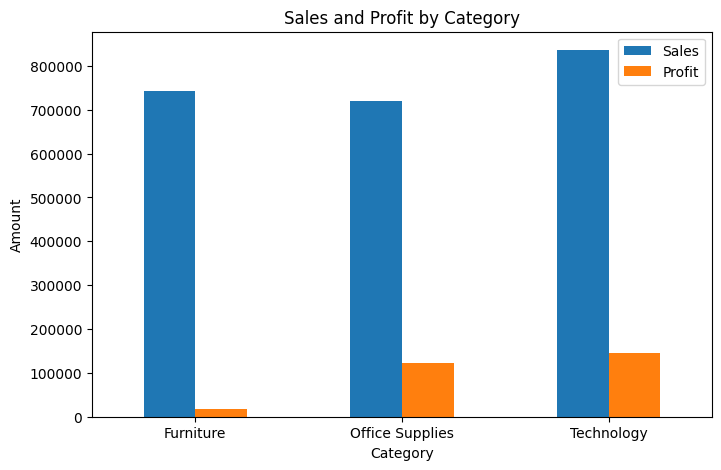

In [ ]:
category_summary.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sales and Profit by Category")
plt.xlabel("Category")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.show()

In [ ]:
subcategory_summary = (
    df.groupby("Sub-Category")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

subcategory_summary

,Profit
Sub-Category,
Copiers,55617.8249
Phones,44515.7306
Accessories,41936.6357
Paper,34053.5693
Binders,30221.7633
Chairs,26590.1663
Storage,21278.8264
Appliances,18138.0054
Furnishings,13059.1436


In [ ]:
sub_category_profit = (
    df.groupby("Sub-Category")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

sub_category_profit

,Profit
Sub-Category,
Copiers,55617.8249
Phones,44515.7306
Accessories,41936.6357
Paper,34053.5693
Binders,30221.7633
Chairs,26590.1663
Storage,21278.8264
Appliances,18138.0054
Furnishings,13059.1436


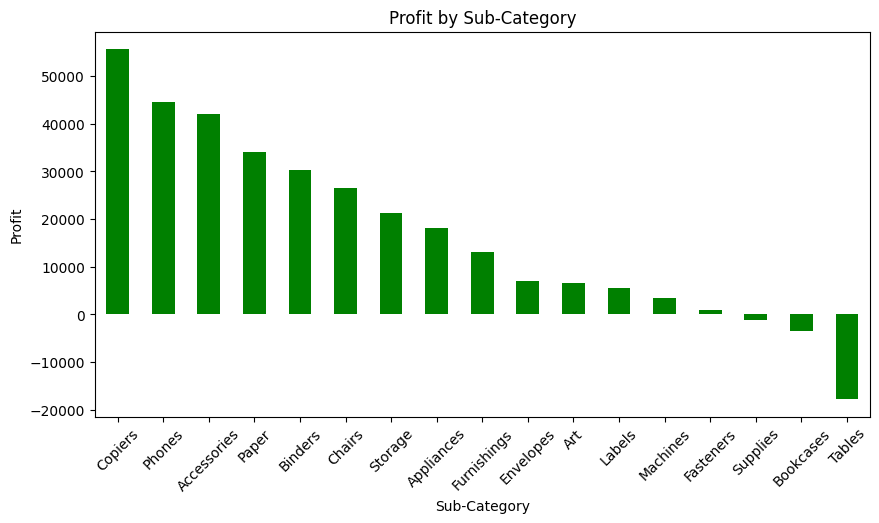

In [ ]:
sub_category_profit.plot(
    kind="bar",
    figsize=(10, 5),
    color="green"
)

plt.title("Profit by Sub-Category")
plt.xlabel("Sub-Category")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.show()

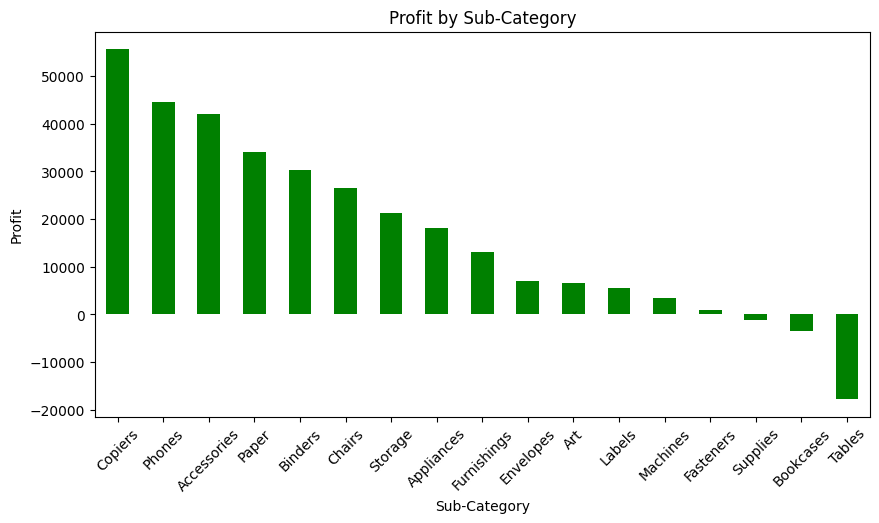

In [ ]:
sub_category_profit.plot(
    kind="bar",
    figsize=(10, 5),
    color="green"
)

plt.title("Profit by Sub-Category")
plt.xlabel("Sub-Category")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.show()

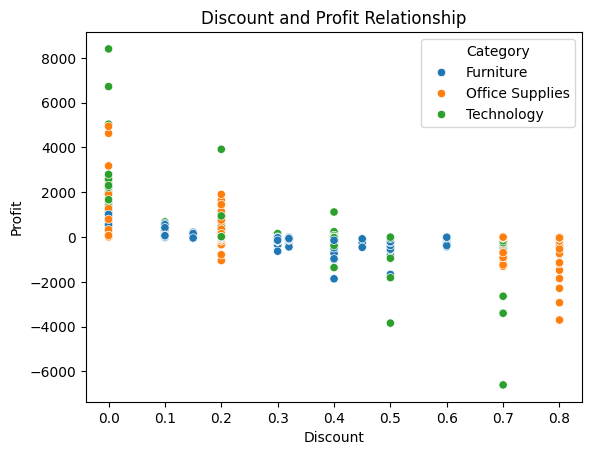

In [ ]:
sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    hue="Category"
)

plt.title("Discount and Profit Relationship")
plt.show()

In [ ]:
discount_summary = df.groupby("Discount").agg(
    Average_Sales=("Sales", "mean"),
    Average_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum"),
    Number_of_Orders=("Order ID", "nunique")
).reset_index()

discount_summary

,Discount,Average_Sales,Average_Profit,Total_Profit,Number_of_Orders
0,0.00,226.742074,66.900292,320987.6032,2644
1,0.10,578.397351,96.055074,9029.1770,89
2,0.15,529.971567,27.288298,1418.9915,51
3,0.20,209.076940,24.702572,90337.3060,2407
4,0.30,454.742974,-45.679636,-10369.2774,211
5,0.32,536.794770,-88.560656,-2391.1377,27
6,0.40,565.134874,-111.927429,-23057.0504,185
7,0.45,498.634000,-226.646464,-2493.1111,10
8,0.50,892.705152,-310.703456,-20506.4281,64
9,0.60,48.150000,-43.077212,-5944.6552,127


In [ ]:
category_discount = df.groupby(
    ["Category", "Discount"]
).agg(
    Average_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum"),
    Number_of_Orders=("Order ID", "nunique")
).reset_index()

category_discount

,Category,Discount,Average_Profit,Total_Profit,Number_of_Orders
0,Furniture,0.00,69.537173,58133.0764,739
1,Furniture,0.10,93.565946,7111.0119,71
2,Furniture,0.15,27.288298,1418.9915,51
3,Furniture,0.20,10.188535,6265.9491,539
4,Furniture,0.30,-48.177103,-10695.3169,207
5,Furniture,0.32,-88.560656,-2391.1377,27
6,Furniture,0.40,-215.831957,-16187.3968,72
7,Furniture,0.45,-226.646464,-2493.1111,10
8,Furniture,0.50,-238.355537,-12871.1990,53
9,Furniture,0.60,-43.077212,-5944.6552,127


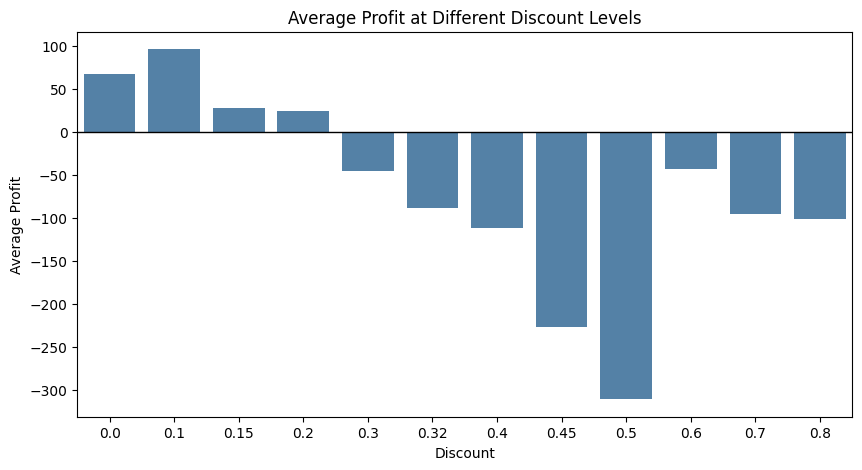

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=discount_summary,
    x="Discount",
    y="Average_Profit",
    color="steelblue"
)

plt.axhline(0, color="black", linewidth=1)
plt.title("Average Profit at Different Discount Levels")
plt.xlabel("Discount")
plt.ylabel("Average Profit")
plt.show()

In [ ]:
segment_summary = df.groupby("Segment").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique"),
    Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean")
).reset_index()

segment_summary

,Segment,Sales,Profit,Orders,Quantity,Average_Discount
0,Consumer,1.161401e+06,134119.2092,2586,19521,0.158141
1,Corporate,7.061464e+05,91979.1340,1514,11608,0.158228
2,Home Office,4.296531e+05,60298.6785,909,6744,0.147128


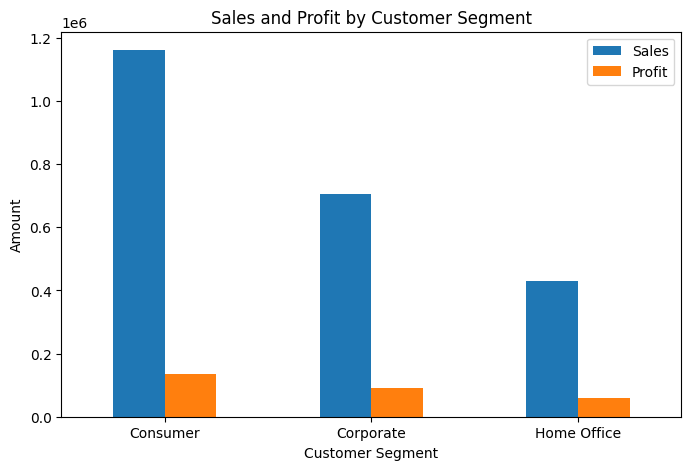

In [ ]:
segment_summary.set_index("Segment")[["Sales", "Profit"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sales and Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.show()

In [ ]:
segment_summary["Profit_Margin"] = (
    segment_summary["Profit"] /
    segment_summary["Sales"]
) * 100

segment_summary


,Segment,Sales,Profit,Orders,Quantity,Average_Discount,Profit_Margin
0,Consumer,1.161401e+06,134119.2092,2586,19521,0.158141,11.548050
1,Corporate,7.061464e+05,91979.1340,1514,11608,0.158228,13.025506
2,Home Office,4.296531e+05,60298.6785,909,6744,0.147128,14.034269


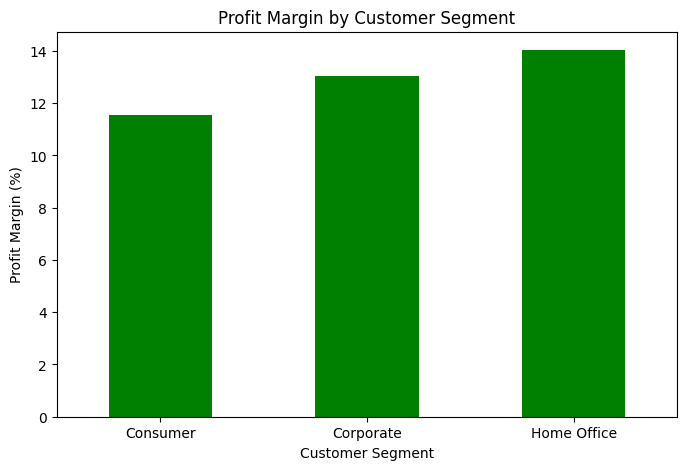

In [ ]:
segment_summary.plot(
    x="Segment",
    y="Profit_Margin",
    kind="bar",
    legend=False,
    color="green",
    figsize=(8, 5)
)

plt.title("Profit Margin by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=0)
plt.show()

In [ ]:
region_summary = df.groupby("Region").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique"),
    Quantity=("Quantity", "sum")
).reset_index()

region_summary["Profit_Margin"] = (
    region_summary["Profit"] /
    region_summary["Sales"]
) * 100

region_summary

,Region,Sales,Profit,Orders,Quantity,Profit_Margin
0,Central,501239.8908,39706.3625,1175,8780,7.921629
1,East,678781.2400,91522.7800,1401,10618,13.483399
2,South,391721.9050,46749.4303,822,6209,11.934342
3,West,725457.8245,108418.4489,1611,12266,14.944831


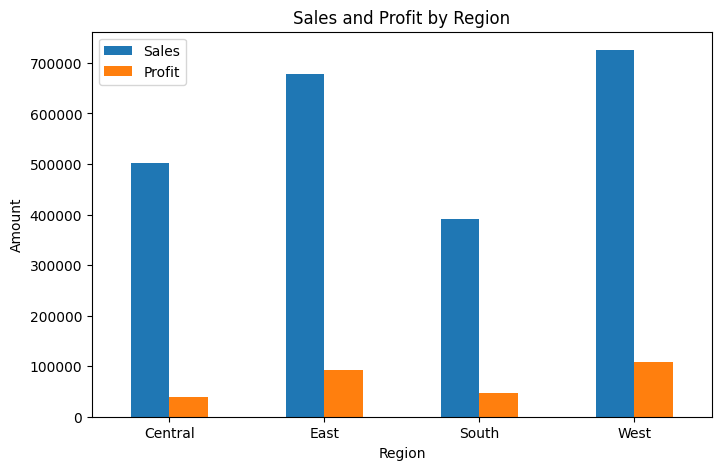

In [ ]:
region_summary.set_index("Region")[["Sales", "Profit"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sales and Profit by Region")
plt.xlabel("Region")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.show()

In [ ]:
region_summary.sort_values("Sales", ascending=False)

,Region,Sales,Profit,Orders,Quantity,Profit_Margin
3,West,725457.8245,108418.4489,1611,12266,14.944831
1,East,678781.2400,91522.7800,1401,10618,13.483399
0,Central,501239.8908,39706.3625,1175,8780,7.921629
2,South,391721.9050,46749.4303,822,6209,11.934342


In [ ]:
region_summary.sort_values(
    "Profit_Margin",
    ascending=False
)

,Region,Sales,Profit,Orders,Quantity,Profit_Margin
3,West,725457.8245,108418.4489,1611,12266,14.944831
1,East,678781.2400,91522.7800,1401,10618,13.483399
2,South,391721.9050,46749.4303,822,6209,11.934342
0,Central,501239.8908,39706.3625,1175,8780,7.921629


In [ ]:
shipping_summary = df.groupby("Ship Mode").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique"),
    Average_Shipping_Days=("Shipping Days", "mean")
).reset_index()

shipping_summary

,Ship Mode,Sales,Profit,Orders,Average_Shipping_Days
0,First Class,3.514284e+05,48969.8399,787,2.182705
1,Same Day,1.283631e+05,15891.7589,264,0.044199
2,Second Class,4.591936e+05,57446.6354,964,3.238046
3,Standard Class,1.358216e+06,164088.7875,2994,5.006535


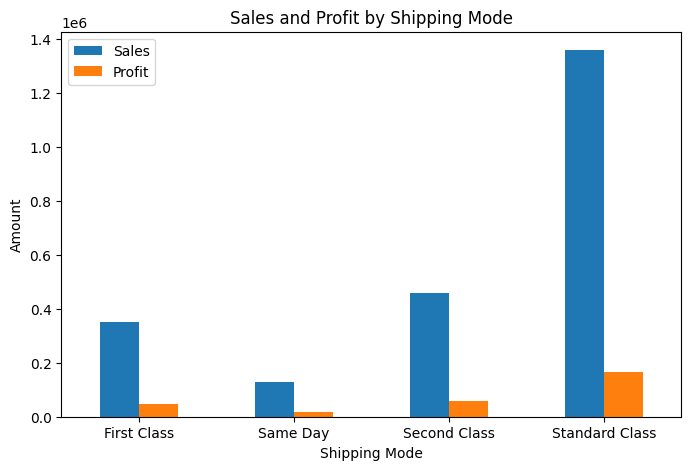

In [ ]:
shipping_summary.set_index("Ship Mode")[
    ["Sales", "Profit"]
].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sales and Profit by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.show()

In [ ]:
shipping_summary.sort_values(
    "Sales",
    ascending=False
)


,Ship Mode,Sales,Profit,Orders,Average_Shipping_Days
3,Standard Class,1.358216e+06,164088.7875,2994,5.006535
2,Second Class,4.591936e+05,57446.6354,964,3.238046
0,First Class,3.514284e+05,48969.8399,787,2.182705
1,Same Day,1.283631e+05,15891.7589,264,0.044199


In [ ]:
shipping_summary.sort_values(
    "Sales",
    ascending=False
)

,Ship Mode,Sales,Profit,Orders,Average_Shipping_Days
3,Standard Class,1.358216e+06,164088.7875,2994,5.006535
2,Second Class,4.591936e+05,57446.6354,964,3.238046
0,First Class,3.514284e+05,48969.8399,787,2.182705
1,Same Day,1.283631e+05,15891.7589,264,0.044199


In [ ]:
shipping_summary.sort_values(
    "Average_Shipping_Days"
)

,Ship Mode,Sales,Profit,Orders,Average_Shipping_Days
1,Same Day,1.283631e+05,15891.7589,264,0.044199
0,First Class,3.514284e+05,48969.8399,787,2.182705
2,Second Class,4.591936e+05,57446.6354,964,3.238046
3,Standard Class,1.358216e+06,164088.7875,2994,5.006535


In [ ]:
shipping_summary["Average_Shipping_Days"] = (
    shipping_summary["Average_Shipping_Days"].round(2)
)

shipping_summary

In [ ]:
shipping_summary["Profit_Margin"] = (
    shipping_summary["Profit"] /
    shipping_summary["Sales"] *
    100
).round(2)

shipping_summary

,Ship Mode,Sales,Profit,Orders,Average_Shipping_Days,Profit_Margin
0,First Class,3.514284e+05,48969.8399,787,2.182705,13.93
1,Same Day,1.283631e+05,15891.7589,264,0.044199,12.38
2,Second Class,4.591936e+05,57446.6354,964,3.238046,12.51
3,Standard Class,1.358216e+06,164088.7875,2994,5.006535,12.08


In [ ]:
shipping_summary["Profit_Margin"] = (
    shipping_summary["Profit"] /
    shipping_summary["Sales"] *
    100
).round(2)

shipping_summary

,Ship Mode,Sales,Profit,Orders,Average_Shipping_Days,Profit_Margin
0,First Class,3.514284e+05,48969.8399,787,2.182705,13.93
1,Same Day,1.283631e+05,15891.7589,264,0.044199,12.38
2,Second Class,4.591936e+05,57446.6354,964,3.238046,12.51
3,Standard Class,1.358216e+06,164088.7875,2994,5.006535,12.08


In [ ]:
shipping_summary["Profit_Per_Order"] = (
    shipping_summary["Profit"] /
    shipping_summary["Orders"]
).round(2)

shipping_summary

,Ship Mode,Sales,Profit,Orders,Average_Shipping_Days,Profit_Margin,Profit_Per_Order
0,First Class,3.514284e+05,48969.8399,787,2.182705,13.93,62.22
1,Same Day,1.283631e+05,15891.7589,264,0.044199,12.38,60.20
2,Second Class,4.591936e+05,57446.6354,964,3.238046,12.51,59.59
3,Standard Class,1.358216e+06,164088.7875,2994,5.006535,12.08,54.81


In [ ]:
shipping_summary.sort_values(
    "Profit_Per_Order",
    ascending=False
)

,Ship Mode,Sales,Profit,Orders,Average_Shipping_Days,Profit_Margin,Profit_Per_Order
0,First Class,3.514284e+05,48969.8399,787,2.182705,13.93,62.22
1,Same Day,1.283631e+05,15891.7589,264,0.044199,12.38,60.20
2,Second Class,4.591936e+05,57446.6354,964,3.238046,12.51,59.59
3,Standard Class,1.358216e+06,164088.7875,2994,5.006535,12.08,54.81


In [ ]:
subcategory_score = df.groupby("Sub-Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity=("Quantity", "sum"),
    Orders=("Order ID", "nunique")
).reset_index()

subcategory_score["Profit_Margin"] = (
    subcategory_score["Profit"] /
    subcategory_score["Sales"] *
    100
)

In [ ]:
for column in ["Sales", "Profit", "Quantity", "Profit_Margin"]:
    minimum = subcategory_score[column].min()
    maximum = subcategory_score[column].max()

    subcategory_score[column + "_Score"] = (
        (subcategory_score[column] - minimum) /
        (maximum - minimum)
    ) * 100

In [ ]:
subcategory_score["Performance_Score"] = (
    subcategory_score["Sales_Score"] * 0.30 +
    subcategory_score["Profit_Score"] * 0.30 +
    subcategory_score["Quantity_Score"] * 0.20 +
    subcategory_score["Profit_Margin_Score"] * 0.20
).round(2)

In [ ]:
subcategory_score = subcategory_score.sort_values(
    "Performance_Score",
    ascending=False
)

subcategory_score[
    [
        "Sub-Category",
        "Sales",
        "Profit",
        "Profit_Margin",
        "Performance_Score"
    ]
]

,Sub-Category,Sales,Profit,Profit_Margin,Performance_Score
13,Phones,330007.0540,44515.7306,13.489327,74.43
3,Binders,203412.7330,30221.7633,14.857361,66.84
12,Paper,78479.2060,34053.5693,43.391837,64.94
0,Accessories,167380.3180,41936.6357,25.054700,61.73
5,Chairs,328449.1030,26590.1663,8.095673,61.67
6,Copiers,149528.0300,55617.8249,37.195585,60.71
14,Storage,223843.6080,21278.8264,9.506113,53.22
9,Furnishings,91705.1640,13059.1436,14.240358,40.94
1,Appliances,107532.1610,18138.0054,16.867517,39.07
10,Labels,12486.3120,5546.2540,44.418672,34.45


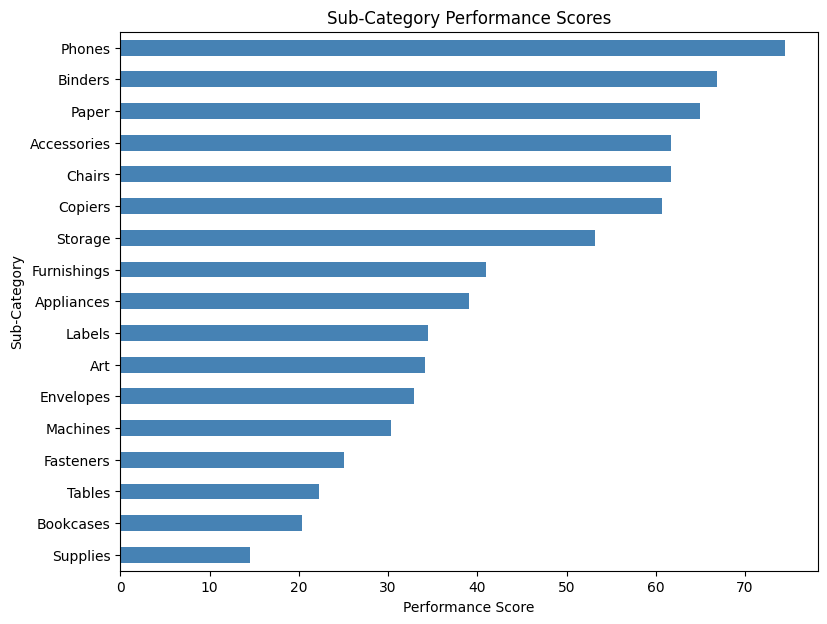

In [ ]:
top_scores = subcategory_score.sort_values(
    "Performance_Score",
    ascending=True
)

top_scores.plot(
    x="Sub-Category",
    y="Performance_Score",
    kind="barh",
    legend=False,
    figsize=(9, 7),
    color="steelblue"
)

plt.title("Sub-Category Performance Scores")
plt.xlabel("Performance Score")
plt.ylabel("Sub-Category")
plt.show()

In [ ]:
subcategory_score["Alternative_Score"] = (
    subcategory_score["Sales_Score"] * 0.20 +
    subcategory_score["Profit_Score"] * 0.40 +
    subcategory_score["Quantity_Score"] * 0.10 +
    subcategory_score["Profit_Margin_Score"] * 0.30
).round(2)

subcategory_score[
    ["Sub-Category", "Performance_Score", "Alternative_Score"]
].sort_values(
    "Alternative_Score",
    ascending=False
)

,Sub-Category,Performance_Score,Alternative_Score
6,Copiers,60.71,74.87
13,Phones,74.43,71.75
12,Paper,64.94,70.89
0,Accessories,61.73,66.40
3,Binders,66.84,61.67
5,Chairs,61.67,57.20
14,Storage,53.22,50.10
10,Labels,34.45,45.30
7,Envelopes,32.86,44.24
1,Appliances,39.07,42.96


In [ ]:
comparison = subcategory_score[
    ["Sub-Category", "Performance_Score", "Alternative_Score"]
].copy()

comparison["Original_Rank"] = (
    comparison["Performance_Score"]
    .rank(ascending=False, method="min")
    .astype(int)
)

comparison["Alternative_Rank"] = (
    comparison["Alternative_Score"]
    .rank(ascending=False, method="min")
    .astype(int)
)

comparison.sort_values("Original_Rank")

,Sub-Category,Performance_Score,Alternative_Score,Original_Rank,Alternative_Rank
13,Phones,74.43,71.75,1,2
3,Binders,66.84,61.67,2,5
12,Paper,64.94,70.89,3,3
0,Accessories,61.73,66.40,4,4
5,Chairs,61.67,57.20,5,6
6,Copiers,60.71,74.87,6,1
14,Storage,53.22,50.10,7,7
9,Furnishings,40.94,40.93,8,11
1,Appliances,39.07,42.96,9,10
10,Labels,34.45,45.30,10,8
